# One factor, many loans: the Vasicek loss distribution of a large portfolio

- **Level:** 1, Fundamentals
- **Prerequisites:** none beyond the entry topic (topic 01, notebooks 01 and 02: how to open an artifact and read a result)
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can:

- say what the one-factor (Vasicek) model assumes about why loans default together, and what the systematic factor is;
- compute, with the engine, the default probability of a loan given the state of the economy, and check that definition by counting defaults among 200,000 simulated loans;
- read the loss distribution of a very large homogeneous portfolio, its quantiles and its density, on the fitted parameters of the commercial and industrial loans of US banks;
- say what a 99.9% loss quantile means for capital, and compute expected loss, value at risk, expected shortfall and unexpected-loss capital for an illustrative book;
- place each observed year of loss rates inside the fitted distribution, and name the worst years.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# The notebook sits three folders below the repository root
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))


riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is the first of the five loan-type files of case C10 (portfolio credit capital), as Contraste commits it: **commercial and industrial loans** of all US commercial banks. The yearly loss rate is built from the Federal Reserve's quarterly charge-off rates, seasonally adjusted, for the years 1985 to 2012 (Board of Governors of the Federal Reserve System, table `chgallsa`, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm; the Board's website content is public domain, licence class `mirror-allowed`). Years 1985 to 2006 are the **fit window** (22 years) and 2007 to 2012 the **evaluation window** (6 years) that the next notebook uses for a back-test.

- **File read:** `data/derived/C10/commercial-industrial.json`, keys `outputs.annual_rates` (one row per year), `outputs.fit` (the fitted PD and correlation) and `outputs.fitted_distribution` (the quantiles the pipeline computed).
- **What the artifact does not hold:** the raw quarterly page. The pipeline reads it once, pinned by its SHA-256, and commits the derived numbers.

The next cell loads the artifact and prints what a loss rate is, the window and the first rows.

In [2]:
# Load the artifact and print the definition of the loss rate, the windows and the first rows
LANG = "en"
doc = json.loads((ROOT / "data" / "derived" / "C10" / "commercial-industrial.json").read_text(encoding="utf-8"))
out = doc["outputs"]
print("loss rate:", out["loss_rate_definition"][LANG])
print("fit window:", out["windows"]["fit"])
print("evaluation window:", out["windows"]["evaluation"])
print("baked by riskvalidation", doc["provenance"]["riskvalidation_version"])

rows = out["annual_rates"]
print("years in the file:", len(rows))
for r in rows[:3]:
    print(r["year"], r["window"], "loss rate", r["loss_rate"], "quarters", r["n_quarters"])

loss rate: Net charge-off rate of the Federal Reserve's charge-off release (All Banks, seasonally adjusted), annualised, as a decimal per year. The annual rate is the mean of the four quarterly rates; a year with a missing quarter has no rate.
fit window: {'first_year': 1985, 'last_year': 2006, 'n_years': 22}
evaluation window: {'first_year': 2007, 'last_year': 2012, 'n_years': 6}
baked by riskvalidation 0.7.0
years in the file: 28
1985 fit loss rate 0.013375 quarters 4
1986 fit loss rate 0.014925 quarters 4
1987 fit loss rate 0.011825 quarters 4


A look at the whole series before any model. The next cell draws the 28 yearly loss rates, with the two windows marked. The model of this notebook will be fitted on the first 22 only.

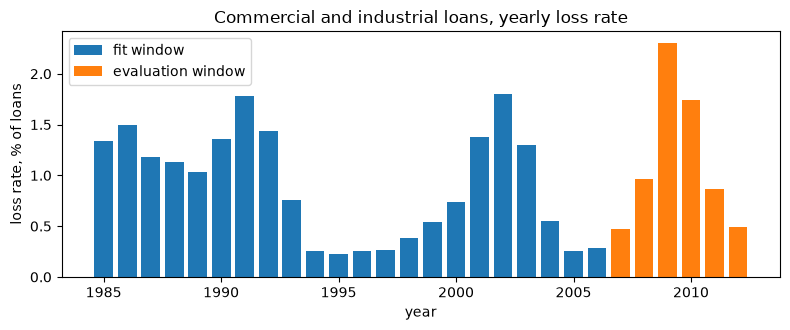

highest year: 2009 rate 0.02303


In [3]:
# Draw the yearly loss rates, colouring the fit window and the evaluation window
years = np.array([r["year"] for r in rows])
rate = np.array([r["loss_rate"] for r in rows])
in_fit = np.array([r["window"] == "fit" for r in rows])

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(years[in_fit], 100 * rate[in_fit], color="tab:blue", label="fit window")
ax.bar(years[~in_fit], 100 * rate[~in_fit], color="tab:orange", label="evaluation window")
ax.set_xlabel("year")
ax.set_ylabel("loss rate, % of loans")
ax.set_title("Commercial and industrial loans, yearly loss rate")
ax.legend()
fig.tight_layout()
plt.show()
print("highest year:", int(years[rate.argmax()]), "rate", round(float(rate.max()), 5))

## Method

### Step 1: why loans default together, and the conditional default probability

The one-factor model of Vasicek (2002) gives every loan a latent asset return made of two independent standard normal parts, one shared by all loans and one of its own (the model foundation and its use in the Basel IRB formula are in Gordy, 2003, https://doi.org/10.1016/S1042-9573(03)00040-8):

$$A_i = \sqrt{\rho}\, Z + \sqrt{1-\rho}\, \varepsilon_i$$

Loan $i$ defaults when $A_i$ falls below the threshold $\Phi^{-1}(\mathrm{PD})$, where $\Phi$ is the standard normal distribution function and PD the through-the-cycle default probability. $Z$ is the **systematic factor**, the state of the economy shared by every loan; a low $Z$ is a bad year. $\rho$ is the **asset correlation**. Given $Z=z$ the loans are independent and each defaults with the conditional probability

$$p(z) = \Phi\!\left(\frac{\Phi^{-1}(\mathrm{PD}) - \sqrt{\rho}\, z}{\sqrt{1-\rho}}\right)$$

The engine's `conditional_pd` computes it. The pipeline fitted PD and correlation to the 22 years of the fit window by maximum likelihood (the next notebook shows how); here we take the fitted values from the artifact. The next cell prints them and the conditional PD for a good, a normal and a bad year.

In [4]:
# Read the fitted PD and correlation and compute the conditional PD in a good, a normal and a bad year
from riskvalidation.engines.vasicek import conditional_pd

ml = out["fit"]["maximum_likelihood"]
pd_hat, rho_hat = ml["pd"]["estimate"], ml["rho"]["estimate"]
print("PD fitted:", round(pd_hat, 6), "| correlation:", round(rho_hat, 6))
print("95% interval of the correlation:", round(ml["rho"]["ci_low"], 4), "to", round(ml["rho"]["ci_high"], 4))

for label, z in (("good year", 1.0), ("normal year", 0.0), ("bad year", -2.0), ("very bad year", -3.0)):
    print(f"{label:16s} z = {z:5.1f} | conditional PD = {float(conditional_pd(pd_hat, rho_hat, z)):.5f}")

PD fitted: 0.009105 | correlation: 0.063677
95% interval of the correlation: 0.0382 to 0.1158
good year        z =   1.0 | conditional PD = 0.00346
normal year      z =   0.0 | conditional PD = 0.00734
bad year         z =  -2.0 | conditional PD = 0.02751
very bad year    z =  -3.0 | conditional PD = 0.04866


The definition can be checked without the formula. In the next cell we fix a bad year ($z=-2$), draw the idiosyncratic part for 200,000 loans, apply the default rule $A_i < \Phi^{-1}(\mathrm{PD})$ and count. This is a check of the definition on 200,000 draws, not a second implementation of the engine: the fraction of defaults must be close to $p(-2)$.

In [5]:
# Count the defaults among 200,000 simulated loans in a year with z = -2 and compare with the conditional PD
rng = np.random.default_rng(2024)
z_bad = -2.0
n_loans = 200_000
asset = np.sqrt(rho_hat) * z_bad + np.sqrt(1 - rho_hat) * rng.standard_normal(n_loans)
defaulted = asset < stats.norm.ppf(pd_hat)

fraction = defaulted.mean()
sd = np.sqrt(fraction * (1 - fraction) / n_loans)
print("simulated default fraction:", round(float(fraction), 5), "+/-", round(float(sd), 5))
print("engine conditional PD:", round(float(conditional_pd(pd_hat, rho_hat, z_bad)), 5))
print("difference in standard errors:", round(float((fraction - conditional_pd(pd_hat, rho_hat, z_bad)) / sd), 2))

simulated default fraction: 0.02787 +/- 0.00037
engine conditional PD: 0.02751
difference in standard errors: 0.97


### Step 2: the loss distribution of a very large portfolio

When the portfolio has very many loans of the same kind, the idiosyncratic parts average out and the fraction of defaults is exactly the conditional PD: $L = p(Z)$. Because $p(z)$ falls as $z$ grows, the distribution function and the quantile of this **large homogeneous portfolio** (LHP) follow in closed form (Vasicek, 2002; Gordy, 2003):

$$P(L \le x) = \Phi\!\left(\frac{\sqrt{1-\rho}\,\Phi^{-1}(x) - \Phi^{-1}(\mathrm{PD})}{\sqrt{\rho}}\right), \qquad \mathrm{VaR}_q = \Phi\!\left(\frac{\Phi^{-1}(\mathrm{PD}) + \sqrt{\rho}\,\Phi^{-1}(q)}{\sqrt{1-\rho}}\right)$$

The engine has them as `lhp_cdf`, `lhp_quantile` and `lhp_pdf`. The 99.9% quantile is the default fraction exceeded once in a thousand years; at $q=0.999$ it is the conditional PD that the IRB capital formula uses (BCBS, 2005). The next cell computes the quantiles at the five levels the artifact holds and puts them beside the pipeline's, with the engine version that baked them.

In [6]:
# Compute the LHP quantiles with the engine and compare them with the committed ones
from riskvalidation.engines.vasicek import lhp_cdf, lhp_pdf, lhp_quantile

print("baked by riskvalidation", doc["provenance"]["riskvalidation_version"])
print(f"{'q':>7s} {'engine':>12s} {'committed':>12s} {'difference':>12s}")
for row in out["fitted_distribution"]["quantiles"]:
    mine = float(lhp_quantile(row["level"], pd_hat, rho_hat))
    print(f"{row['level']:7.3f} {mine:12.6f} {row['value']:12.6f} {mine - row['value']:12.2e}")

# The distribution function at a few loss levels: how likely is a year with a loss rate at most x
for x in (0.005, 0.01, 0.02, 0.04):
    print(f"P(L <= {x:.3f}) = {float(lhp_cdf(x, pd_hat, rho_hat)):.4f}")

baked by riskvalidation 0.7.0
      q       engine    committed   difference
  0.500     0.007338     0.007338    -3.26e-12
  0.900     0.017598     0.017598    -1.92e-11
  0.950     0.022144     0.022144    -1.03e-11
  0.990     0.033355     0.033355     1.21e-11
  0.999     0.051085     0.051085    -5.64e-12
P(L <= 0.005) = 0.3016
P(L <= 0.010) = 0.6689
P(L <= 0.020) = 0.9309
P(L <= 0.040) = 0.9959


The density tells the same story as a picture. The next cell draws the LHP density of the default fraction, marks the 50%, 99% and 99.9% quantiles, and puts the 22 fit-window years below it as ticks. A well-fitted model has its observed years scattered under the body of the density, with none far in the right tail.

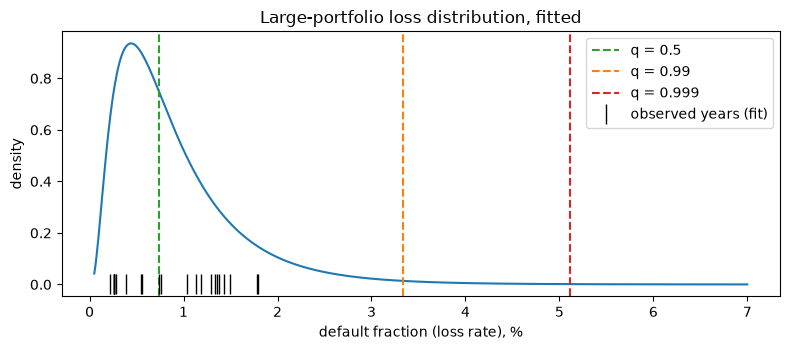

In [7]:
# Draw the LHP density with its quantiles and the observed fit-window years as ticks
grid = np.linspace(0.0005, 0.07, 600)
density = lhp_pdf(grid, pd_hat, rho_hat)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(100 * grid, density / 100, color="tab:blue")
for q, color in ((0.5, "tab:green"), (0.99, "tab:orange"), (0.999, "tab:red")):
    xq = float(lhp_quantile(q, pd_hat, rho_hat))
    ax.axvline(100 * xq, color=color, linestyle="--", label=f"q = {q}")
ax.plot(100 * rate[in_fit], np.zeros(in_fit.sum()), "|", color="black", markersize=14, label="observed years (fit)")
ax.set_xlabel("default fraction (loss rate), %")
ax.set_ylabel("density")
ax.set_title("Large-portfolio loss distribution, fitted")
ax.legend()
fig.tight_layout()
plt.show()

### Step 3: what a 99.9% loss quantile means for capital

A bank does not hold capital against the average loss, which it prices in. It holds it against the **unexpected** loss: the gap between a very bad year and the expected one. For a book of total exposure $E$ and expected loss given default $\mathrm{LGD}$ the large-portfolio measures are the expected loss $\mathrm{EL}=E\cdot \mathrm{LGD}\cdot \mathrm{PD}$, the value at risk $\mathrm{VaR}_q = E\cdot \mathrm{LGD}\cdot \mathrm{VaR}_q(L)$, the expected shortfall $\mathrm{ES}_q$, the mean loss in the worst $1-q$ of years (Acerbi and Tasche, 2002, https://doi.org/10.1016/S0378-4266(02)00283-2), and the unexpected-loss capital $\mathrm{EC}_q=\mathrm{VaR}_q-\mathrm{EL}$. The engine returns them in `lhp_measures`. We use the illustrative book of the case: 100 million USD of exposure and an LGD of 45%; it is a constructed book, never a bank's.

In [8]:
# Compute EL, VaR, ES and capital of the illustrative 100-million book at 99% and 99.9%, and compare with the committed first rung
from riskvalidation.portfolio.portfolio import lhp_measures

total_ead = out["portfolio"]["total_ead"]
lgd = out["portfolio"]["lgd_mean"]
measures = lhp_measures(total_ead, lgd, pd_hat, rho_hat, (0.99, 0.999))
c1 = next(r for r in out["rungs"] if r["id"] == "c1-lhp")["measures"]

print("exposure:", f"{total_ead:,.0f}", out["currency"], "| LGD:", lgd)
for m, committed in zip(measures, c1):
    print(f"q = {m.level}: EL = {m.el:,.0f} | VaR = {m.var:,.0f} | ES = {m.es:,.0f} | capital = {m.ec:,.0f}")
    print("        committed VaR:", f"{committed['var']:,.0f}", "| committed ES:", f"{committed['es']:,.0f}")
print("capital at 99.9% as a share of exposure:", round(measures[-1].ec / total_ead, 5))

exposure: 100,000,000 USD | LGD: 0.45
q = 0.99: EL = 409,721 | VaR = 1,500,956 | ES = 1,844,768 | capital = 1,091,236
        committed VaR: 1,500,956 | committed ES: 1,844,768
q = 0.999: EL = 409,721 | VaR = 2,298,833 | ES = 2,680,019 | capital = 1,889,113
        committed VaR: 2,298,834 | committed ES: 2,680,019
capital at 99.9% as a share of exposure: 0.01889


### Step 4: where each observed year falls

The distribution function turns each year's loss rate into a position in the fitted distribution: $u = P(L \le x)$, a number between 0 and 1. A year at $u=0.99$ is a one-in-a-hundred year. The same year also implies a value of the systematic factor, the inverse of $p(z)$ (the Z-factor of Belkin, Suchower and Forest, 1998; here a derivation from the formula above, not a quoted equation):

$$\hat z_t = \frac{\Phi^{-1}(\mathrm{PD}) - \sqrt{1-\rho}\,\Phi^{-1}(x_t)}{\sqrt{\rho}}$$

The engine's `implied_factor` computes it. The next cell computes both for the 28 years, checks them against the columns the artifact committed, and lists the three worst years.

In [9]:
# Compute the position and the implied factor of each year, compare with the committed columns and list the worst years
from riskvalidation.engines.vasicek import implied_factor

u = np.array([float(lhp_cdf(x, pd_hat, rho_hat)) for x in rate])
z_hat = np.array([float(implied_factor(x, pd_hat, rho_hat)) for x in rate])
u_file = np.array([r["fitted_cdf"] for r in rows])
z_file = np.array([r["implied_factor"] for r in rows])
print("largest gap to the committed position:", f"{np.abs(u - u_file).max():.1e}")
print("largest gap to the committed factor:", f"{np.abs(z_hat - z_file).max():.1e}")

worst = np.argsort(-u)[:3]
for k in worst:
    print(int(years[k]), rows[k]["window"], "loss rate", round(float(rate[k]), 5), "| u =", round(float(u[k]), 4), "| z =", round(float(z_hat[k]), 3))
print("years above the 99% quantile:", int((u > 0.99).sum()), "| above the 99.9% quantile:", int((u > 0.999).sum()))

largest gap to the committed position: 7.0e-10
largest gap to the committed factor: 5.3e-09
2009 evaluation loss rate 0.02303 | u = 0.9562 | z = -1.708
2002 fit loss rate 0.01798 | u = 0.9057 | z = -1.315
1991 fit loss rate 0.01785 | u = 0.9038 | z = -1.304
years above the 99% quantile: 0 | above the 99.9% quantile: 0


## Results

- **The conditional PD moves a lot with the economy.** The through-the-cycle PD of the fit is 0.9% a year, but the conditional PD is 0.35% in a good year (z = 1), 0.73% in a normal one, 2.75% in a bad one (z = -2) and 4.87% in a very bad one (z = -3). The defaults of different loans are not independent: they are driven by one shared factor, and that is what makes the loss distribution of a portfolio so much wider than a count of independent loans would be.
- **The definition holds.** Counting defaults among 200,000 simulated loans at z = -2 gives 2.787% with a standard error of 0.037%, against the engine's 2.751%: a difference of 0.97 standard errors, which is what chance alone produces.
- **The large-portfolio distribution is skewed to the right.** The fitted median loss rate is 0.73% and the 99% and 99.9% quantiles are 3.34% and 5.11%. The engine and the pipeline agree to about 1e-11, the rounding of the committed file; the pipeline baked the file with engine 0.7.0 and the installed engine is 0.8.1, so this agreement is a reproducibility check across two releases.
- **What the quantile means for capital.** On 100 million USD of exposure at an LGD of 45%, the expected loss is 409,721 USD, the 99.9% value at risk is 2,298,833 USD and the 99.9% expected shortfall is 2,680,019 USD. The unexpected-loss capital at 99.9% is 1,889,113 USD, 1.9% of the exposure. The 99% and 99.9% measures differ because capital is a statement about how bad a rare year can be, not about the average one.
- **The observed years sit inside the fitted distribution.** The worst year of the whole series, 2009, with a loss rate of 2.30%, is at position 0.956 of the fitted distribution; the next two, 2002 and 1991, are near 0.90. No year is above the 99% quantile. That is expected: with 28 years a one-in-a-hundred year is unlikely to appear, and a one-in-a-thousand year (the level capital is set at) cannot be seen at all, so these years can neither confirm nor refute the 99.9% quantile.

What this notebook does not show: how the PD and the correlation were estimated and how uncertain they are (notebook 02), what changes when the portfolio is finite and concentrated (notebooks 03 to 05), and how the result compares with the regulatory IRB capital (notebooks 02 and 07). The book is illustrative, never a bank's.

## Summary

- The one-factor model explains joint defaults with one shared systematic factor; given the factor, loans default independently with the conditional PD `conditional_pd`.
- For a very large homogeneous portfolio the default fraction is the conditional PD, so its distribution, density and quantiles are closed formulas (`lhp_cdf`, `lhp_pdf`, `lhp_quantile`), reproduced here to about 1e-11 against the committed file.
- A 99.9% quantile is a once-in-a-thousand-years loss rate; capital is the unexpected loss, the gap between that quantile and the expected loss, and `lhp_measures` returns EL, VaR, ES and capital for a book.
- Each observed year has a position in the fitted distribution and an implied systematic factor; 28 years of data cannot test a 99.9% quantile.

**What to try next.** Change `z_bad` in the simulation check to 0 and to 1 and watch the fraction follow the conditional PD. Then open notebook 02, where the PD and the correlation are estimated from the loss rates and their uncertainty is measured.

## References

- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- BCBS, Basel Framework, CRE31: IRB approach, risk weight functions for corporate, bank, sovereign and retail exposures. https://www.bis.org/basel_framework/chapter/CRE/31.htm
- Acerbi, C. and Tasche, D. (2002), On the coherence of expected shortfall, Journal of Banking and Finance 26(7):1487-1503. https://doi.org/10.1016/S0378-4266(02)00283-2
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162 (reprinted in Vasicek, O. (2015), Finance, Economics and Mathematics, Wiley, doi 10.1002/9781119186229.ch19).
- Belkin, B., Suchower, S. and Forest, L. (1998), A one-parameter representation of credit risk and transition matrices, CreditMetrics Monitor, as cited by the engine's `engines.vasicek` module.
- BCBS (2005), An Explanatory Note on the Basel II IRB Risk Weight Functions, https://www.bis.org/publications/explanatory-note-basel-ii-irb-risk-weight-functions.pdf.